# Learning Rate & Training Stability in a Small CNN

This notebook is an experiment about "How does learning rate change the training curve of a small CNN, and where does training become unstable?". 
Read the short explanations, run the cells in order, change for other learning rate and compare it with the others.

## What we are investigating

A *learning rate* controls the step size an optimizer uses when updating a neural network's parameters (weights and biases). If the steps are too small, learning may be slow. If they are too large, updates may overshoot useful values and training may become unstable.

We will change **only the learning rate** and compare five values:

- `0.00001`
- `0.0001`
- `0.001` (baseline)
- `0.01`
- `0.1`

We will use the same Fashion-MNIST data split, CNN architecture, Adam optimizer, batch size, and number of epochs for every run. Each learning rate is trained three times, once for each of three random seeds (42, 43, 44), so we can tell real differences from random noise.

## 1. Experiment map

| Item | Choice |
|---|---|
| Dataset | Fashion-MNIST (grayscale clothing images, 10 classes) |
| Training subset | 10,000 images |
| Validation subset | 6,000 images |
| Test set | Not used to choose or compare learning rates |
| Model | Small CNN (421,834 trainable parameters) |
| Optimizer | Adam |
| Learning rates | 0.00001, 0.0001, 0.001, 0.01, 0.1 |
| Batch size | 64 |
| Epochs | 4 |
| Data split seed | 42 (one fixed split reused in every run) |
| Training seeds | 42, 43, 44 (control initial weights, batch order and dropout) |
| Total runs | 5 learning rates × 3 seeds = 15 |
| Loss | Cross-entropy loss |

We will be training on a subset to keep the experiment manageable. Validation data is separate from the examples used to update the model. We use it to compare how well each run generalizes during training. We will not use test accuracy to select a learning rate.

During training, the model makes predictions, calculates a loss (a measure of prediction error), and the optimizer updates the model's parameters.

A simplified gradient-descent update is:

$$w_{\text{new}} = w_{\text{old}} - \alpha \times \text{gradient}$$

Where:

- $w_{\text{old}}$ is the current weight.
- $\alpha$ is the learning rate.
- The gradient indicates how the weight should change.
- $w_{\text{new}}$ is the updated weight.

This equation illustrates the role of the learning rate as a step-size control. Our experiment uses **Adam**, an adaptive optimizer, so its exact update rule is more involved; the learning rate still scales the size of its parameter updates.

### What might the curves show?

- **Very small learning rate:** loss may decrease slowly because updates are tiny.
- **Useful learning rate:** loss may decrease steadily.
- **Too-large learning rate:** loss may fluctuate, increase, or become non-finite. This can be evidence of unstable training.

These are expectations to investigate, not results to assume.

## 3. Install/import libraries

If you are running this in Google Colab, PyTorch and torchvision are usually preinstalled. If an import fails in your local environment, install the missing packages in your terminal or notebook environment.

In [1]:
import copy
import math
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch: 2.14.0+cpu
Device: cpu


## 4. Make the experiment reproducible

A random seed helps make the data split, initial model weights, and batch order repeatable. Exact results can still vary slightly across hardware and software versions, but fixing the seed makes the comparison fairer.

We reset the seed before each run. For a given seed, every learning rate starts from the same initial model weights and sees the same shuffled batch order.

We repeat the whole comparison with **three seeds**. A different seed means a different random starting point for the network, so the spread across seeds shows how much results change just from luck. If two learning rates differ by less than that spread, we should not claim one is better.

In [2]:
SEED = 42  # fixes the train/validation split for every run
SEEDS = [42, 43, 44]  # training seeds: initial weights, batch order, dropout
BATCH_SIZE = 64
EPOCHS = 4
TRAIN_SUBSET_SIZE = 10_000
VALIDATION_SIZE = 6_000

LEARNING_RATES = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Deterministic settings improve repeatability where supported.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("Using device:", DEVICE)
print("Learning rates:", LEARNING_RATES)
print("Training seeds:", SEEDS)

Using device: cpu
Learning rates: [1e-05, 0.0001, 0.001, 0.01, 0.1]
Training seeds: [42, 43, 44]


## 5. Load Fashion-MNIST and create fixed train/validation subsets

Fashion-MNIST contains 28 × 28 grayscale images in 10 clothing categories. The official training split contains 60,000 images. We will take 10,000 for training and a separate 6,000 for validation from that training split.

The official Fashion-MNIST test split is **not loaded or used** in this experiment. Learning rates are compared using the validation subset only; no test-set performance is used to choose a setting.


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Create one fixed split that is reused for all learning-rate runs.
split_generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(full_train_dataset), generator=split_generator).tolist()

train_indices = indices[:TRAIN_SUBSET_SIZE]
validation_indices = indices[TRAIN_SUBSET_SIZE:TRAIN_SUBSET_SIZE + VALIDATION_SIZE]

train_dataset = Subset(full_train_dataset, train_indices)
validation_dataset = Subset(full_train_dataset, validation_indices)

print("Full training split:", len(full_train_dataset))
print("Training subset:", len(train_dataset))
print("Validation subset:", len(validation_dataset))

Full training split: 60000
Training subset: 10000
Validation subset: 6000


## 6. Small CNN

A **Convolutional Neural Network (CNN)** is commonly used for image tasks. Convolution layers learn visual patterns such as edges and shapes. Pooling layers reduce the spatial size of feature maps. The final linear layers use the learned features to predict one of the 10 clothing classes.

The architecture stays exactly the same for every learning-rate run. This CNN has **421,834 trainable parameters** (weights and biases that are updated during training); the next code cell calculates and prints this count.


In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# Display the number of trainable parameters.
set_seed()
model_check = SmallCNN()
parameter_count = sum(p.numel() for p in model_check.parameters() if p.requires_grad)
print(f"Trainable parameters: {parameter_count:,}")

Trainable parameters: 421,834


## 7. Training and Evaluation functions

**Training loss** measures prediction error on batches that are used to update the model.

**Validation loss** measures prediction error on separate data that does not update the model.

Accuracy is the percentage of images classified correctly. We record both loss and accuracy after each epoch so that the learning curves show more than a single final score.

If an unusually high learning rate causes non-finite values (such as `NaN` or infinity), the run is stopped safely and recorded. This is one clear sign of numerical instability.

In [5]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        # Detect numerical instability rather than silently storing invalid values.
        if not torch.isfinite(loss):
            return float("nan"), float("nan"), False

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_examples += batch_size

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples
    return average_loss, accuracy, True

## 8. Run the controlled comparison

Each run creates a fresh CNN. For every learning rate we train three times, once per seed in `SEEDS`, so there are 15 runs in total (about three times longer than a single-seed run). The same fixed training and validation subsets are reused. Only `lr` changes in the Adam optimizer.

We use four epochs to keep the runs short. This is a small exploratory experiment, so a short run may not reveal the eventual best performance of every setting. 

In [6]:
def make_loaders(seed=SEED):
    # Same batch order for every learning rate that uses the same seed.
    loader_generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=loader_generator,
        num_workers=0
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )
    return train_loader, validation_loader


def train_one_learning_rate(lr, seed):
    set_seed(seed)
    model = SmallCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_loader, validation_loader = make_loaders(seed)
    history = {
        "epoch": [],
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    status = "completed"
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc, train_ok = run_epoch(model, train_loader, optimizer)
        if not train_ok:
            status = "unstable: non-finite training loss"
            break

        val_loss, val_acc, val_ok = run_epoch(model, validation_loader)
        if not val_ok:
            status = "unstable: non-finite validation loss"
            break

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(
            f"LR={lr:g} | seed={seed} | Epoch {epoch}/{EPOCHS} | "
            f"train loss={train_loss:.4f}, val loss={val_loss:.4f}, "
            f"train acc={train_acc:.3f}, val acc={val_acc:.3f}"
        )

    elapsed = time.time() - start_time
    return history, status, elapsed


# Results are stored by (learning_rate, seed).
all_histories = {}
run_status = {}
run_times = {}

for lr in LEARNING_RATES:
    for seed in SEEDS:
        print("\n" + "=" * 65)
        print(f"Training with learning rate = {lr:g}, seed = {seed}")
        history, status, elapsed = train_one_learning_rate(lr, seed)
        all_histories[(lr, seed)] = history
        run_status[(lr, seed)] = status
        run_times[(lr, seed)] = elapsed
        print(f"Status: {status} | Time: {elapsed:.1f} seconds")


Training with learning rate = 1e-05, seed = 42
LR=1e-05 | seed=42 | Epoch 1/4 | train loss=1.8167, val loss=1.3958, train acc=0.496, val acc=0.710
LR=1e-05 | seed=42 | Epoch 2/4 | train loss=1.1971, val loss=0.9783, train acc=0.684, val acc=0.743
LR=1e-05 | seed=42 | Epoch 3/4 | train loss=0.9304, val loss=0.8019, train acc=0.730, val acc=0.772
LR=1e-05 | seed=42 | Epoch 4/4 | train loss=0.8040, val loss=0.7027, train acc=0.749, val acc=0.781
Status: completed | Time: 34.6 seconds

Training with learning rate = 1e-05, seed = 43
LR=1e-05 | seed=43 | Epoch 1/4 | train loss=1.7996, val loss=1.3411, train acc=0.508, val acc=0.722
LR=1e-05 | seed=43 | Epoch 2/4 | train loss=1.1482, val loss=0.9345, train acc=0.702, val acc=0.752
LR=1e-05 | seed=43 | Epoch 3/4 | train loss=0.8918, val loss=0.7641, train acc=0.740, val acc=0.774
LR=1e-05 | seed=43 | Epoch 4/4 | train loss=0.7679, val loss=0.6694, train acc=0.755, val acc=0.788
Status: completed | Time: 41.3 seconds

Training with learning ra

## 9. Results table

First we list every individual run, then we summarise each learning rate as the **mean and standard deviation across seeds** of the last recorded epoch. Runs that stopped early because of non-finite loss are listed in the per-run table with their status, and they are left out of the final-run averages (the `runs_completed` column shows how many seeds were averaged).

The learning-curve figures below use every epoch that was successfully recorded, including the earlier epochs of a run that stopped later. The number of seeds contributing to a curve can therefore change from one epoch to the next.

Do not describe the highest mean validation accuracy as a universal best learning rate. It is only the best observed value under this dataset subset, model, optimizer, three seeds, and short training schedule. With only three seeds the standard deviation is a rough guide, not a precise measure.


In [7]:
# --- Per-run table: one row for every (learning rate, seed) run ---
per_run_rows = []

for lr in LEARNING_RATES:
    for seed in SEEDS:
        h = all_histories[(lr, seed)]
        done = len(h["epoch"]) > 0
        per_run_rows.append({
            "learning_rate": lr,
            "seed": seed,
            "epochs_completed": len(h["epoch"]),
            "final_train_loss": h["train_loss"][-1] if done else np.nan,
            "final_val_loss": h["val_loss"][-1] if done else np.nan,
            "final_train_accuracy": h["train_accuracy"][-1] if done else np.nan,
            "final_val_accuracy": h["val_accuracy"][-1] if done else np.nan,
            "status": run_status[(lr, seed)],
            "seconds": run_times[(lr, seed)]
        })

per_run_df = pd.DataFrame(per_run_rows)
print("Every individual run:")
display(per_run_df.style.format({
    "learning_rate": "{:.5g}",
    "final_train_loss": "{:.4f}",
    "final_val_loss": "{:.4f}",
    "final_train_accuracy": "{:.2%}",
    "final_val_accuracy": "{:.2%}",
    "seconds": "{:.1f}"
}, na_rep="n/a"))

# --- Summary table: mean and standard deviation across seeds ---
metric_columns = ["final_train_loss", "final_val_loss", "final_train_accuracy", "final_val_accuracy"]
summary_rows = []

for lr in LEARNING_RATES:
    runs = per_run_df[(per_run_df["learning_rate"] == lr) & (per_run_df["status"] == "completed")]
    row = {"learning_rate": lr, "runs_completed": f"{len(runs)}/{len(SEEDS)}"}
    for col in metric_columns:
        row[col + "_mean"] = runs[col].mean() if len(runs) > 0 else np.nan
        row[col + "_std"] = runs[col].std(ddof=1) if len(runs) > 1 else np.nan
    summary_rows.append(row)

results_df = pd.DataFrame(summary_rows)
print("\nMean and standard deviation across seeds (completed runs only):")
display(results_df.style.format({
    "learning_rate": "{:.5g}",
    "final_train_loss_mean": "{:.4f}", "final_train_loss_std": "{:.4f}",
    "final_val_loss_mean": "{:.4f}", "final_val_loss_std": "{:.4f}",
    "final_train_accuracy_mean": "{:.2%}", "final_train_accuracy_std": "{:.2%}",
    "final_val_accuracy_mean": "{:.2%}", "final_val_accuracy_std": "{:.2%}"
}, na_rep="n/a"))


# --- Helpers used by the figures below ---
def curve_stats(lr, key):
    """Per-epoch mean/std using every seed with a recorded value for that epoch."""
    means, stds, counts = [], [], []
    for epoch_index in range(EPOCHS):
        values = [
            all_histories[(lr, seed)][key][epoch_index]
            for seed in SEEDS
            if len(all_histories[(lr, seed)][key]) > epoch_index
        ]
        counts.append(len(values))
        if values:
            means.append(float(np.mean(values)))
            stds.append(float(np.std(values, ddof=1)) if len(values) > 1 else 0.0)
        else:
            means.append(np.nan)
            stds.append(np.nan)

    valid_epochs = [i for i, count in enumerate(counts) if count > 0]
    if not valid_epochs:
        return None

    x = np.array([i + 1 for i in valid_epochs])
    mean = np.array([means[i] for i in valid_epochs])
    std = np.array([stds[i] for i in valid_epochs])
    n_per_epoch = np.array([counts[i] for i in valid_epochs])
    return x, mean, std, n_per_epoch


def plot_mean_curves(ax, key, title, ylabel, ylim=None):
    for lr in LEARNING_RATES:
        stats = curve_stats(lr, key)
        if stats is None:
            continue
        x, mean, std, counts = stats
        count_label = ",".join(str(int(n)) for n in counts)
        ax.plot(x, mean, marker="o", label=f"LR={lr:g} (n by epoch: {count_label})")
        ax.fill_between(x, mean - std, mean + std, alpha=0.2)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, EPOCHS + 1))
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)


Every individual run:


,learning_rate,seed,epochs_completed,final_train_loss,final_val_loss,final_train_accuracy,final_val_accuracy,status,seconds
0,1e-05,42,4,0.8040,0.7027,74.89%,78.12%,completed,34.6
1,1e-05,43,4,0.7679,0.6694,75.49%,78.78%,completed,41.3
2,1e-05,44,4,0.7969,0.6940,74.95%,78.00%,completed,43.1
3,0.0001,42,4,0.3995,0.3696,86.28%,87.07%,completed,34.4
4,0.0001,43,4,0.3952,0.3726,85.96%,86.95%,completed,37.1
5,0.0001,44,4,0.3973,0.3686,86.12%,87.47%,completed,32.8
6,0.001,42,4,0.3173,0.3119,88.23%,88.33%,completed,32.0
7,0.001,43,4,0.3135,0.3112,88.63%,88.72%,completed,33.0
8,0.001,44,4,0.3036,0.3213,88.68%,88.37%,completed,33.7
9,0.01,42,4,0.6051,0.4510,76.80%,83.75%,completed,33.9



Mean and standard deviation across seeds (completed runs only):


,learning_rate,runs_completed,final_train_loss_mean,final_train_loss_std,final_val_loss_mean,final_val_loss_std,final_train_accuracy_mean,final_train_accuracy_std,final_val_accuracy_mean,final_val_accuracy_std
0,1e-05,3/3,0.7896,0.0191,0.6887,0.0172,75.11%,0.33%,78.30%,0.42%
1,0.0001,3/3,0.3973,0.0022,0.3702,0.0021,86.12%,0.16%,87.16%,0.27%
2,0.001,3/3,0.3115,0.0070,0.3148,0.0056,88.51%,0.25%,88.47%,0.21%
3,0.01,3/3,0.5430,0.0635,0.4108,0.0357,79.40%,2.69%,84.98%,1.21%
4,0.1,3/3,1.8402,0.8147,1.7783,0.9289,28.74%,32.73%,31.17%,36.34%


## 10. Figure 1 — Training and validation loss 

A learning curve plots a metric over training epochs. This figure compares training loss and validation loss for every learning rate.

**How to read it:** The horizontal axis is the epoch; the vertical axis is loss. Look for steady decreases, slow progress, sharp fluctuations, or loss that rises rather than settles.

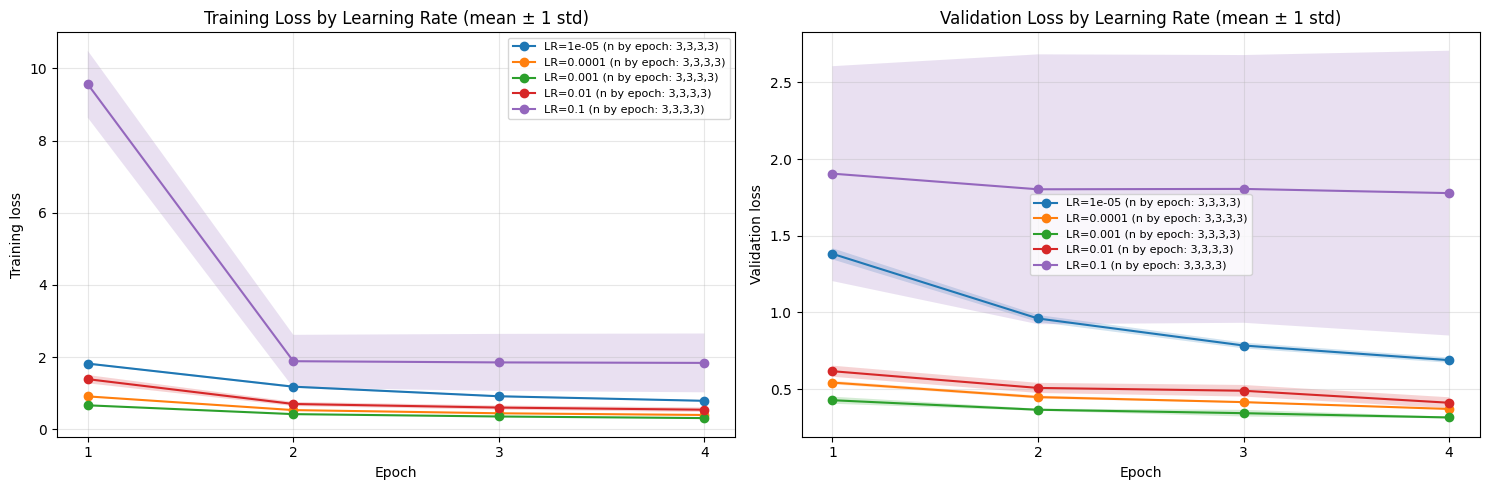

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_mean_curves(axes[0], "train_loss", "Training Loss by Learning Rate (mean ± 1 std)", "Training loss")
plot_mean_curves(axes[1], "val_loss", "Validation Loss by Learning Rate (mean ± 1 std)", "Validation loss")

# Optional: if one learning rate has a huge loss that squashes the others, try
# axes[1].set_yscale("log") to see all curves clearly.

plt.tight_layout()
plt.show()

Mean training and validation loss across epochs for five learning-rate settings. Each point uses all seeds that recorded that epoch; the legend shows the number of contributing seeds at each epoch, and the shaded band is ±1 standard deviation. If a run stopped early because of non-finite loss, its earlier recorded epochs remain visible. The curves show how prediction error changes during training and whether validation error follows a similar pattern.


## 11. Figure 2 — Training and validation accuracy

Loss tells us about the size of prediction errors, while accuracy tells us the proportion of correct classifications. Both are useful because a run can show changes in loss that are not obvious from accuracy alone.

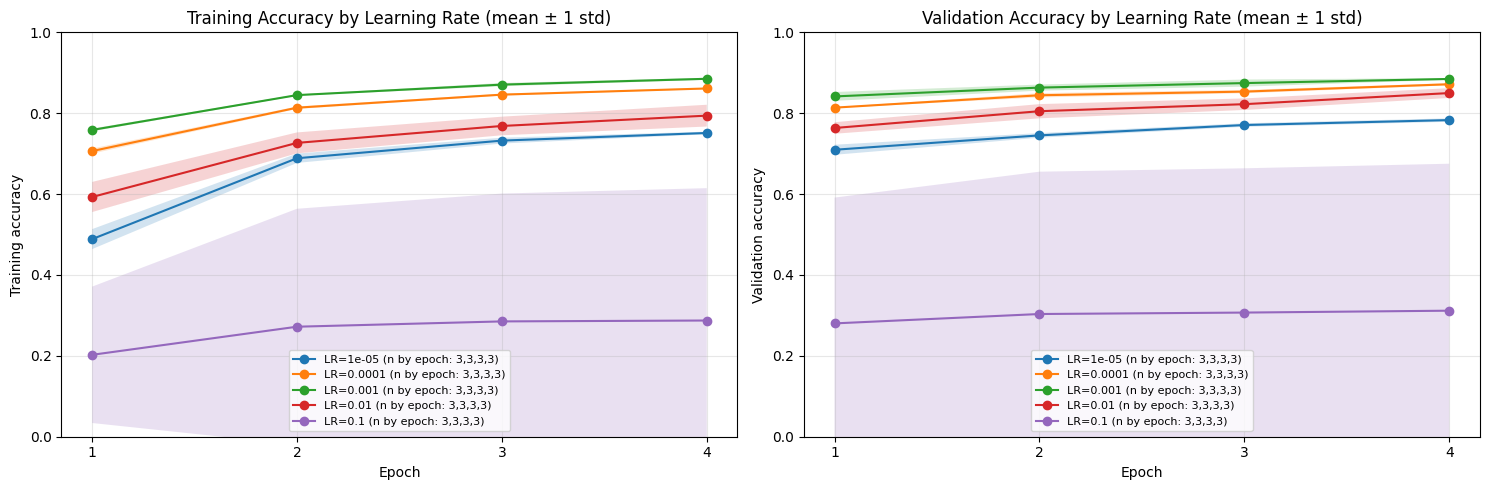

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_mean_curves(axes[0], "train_accuracy", "Training Accuracy by Learning Rate (mean ± 1 std)", "Training accuracy", ylim=(0, 1))
plot_mean_curves(axes[1], "val_accuracy", "Validation Accuracy by Learning Rate (mean ± 1 std)", "Validation accuracy", ylim=(0, 1))

plt.tight_layout()
plt.show()

Mean training and validation accuracy across epochs for each learning rate, with a ±1 standard deviation band. Each epoch includes all seeds that successfully recorded that epoch; the legend reports the number of contributing seeds at each epoch. Earlier results from runs that stopped later are retained in the curves.


## 12. Figure 3 — Final validation loss comparison

This chart compares the final recorded validation loss for each learning rate **among runs that completed all four epochs**. The line shows the mean across completed seeds with error bars of ±1 standard deviation, and the gray dots are the individual completed runs. Runs that stopped early are not included in this final-epoch comparison; their recorded earlier epochs are still shown in Figures 1 and 2. This is a compact summary, but it should not replace the epoch-by-epoch learning curves.


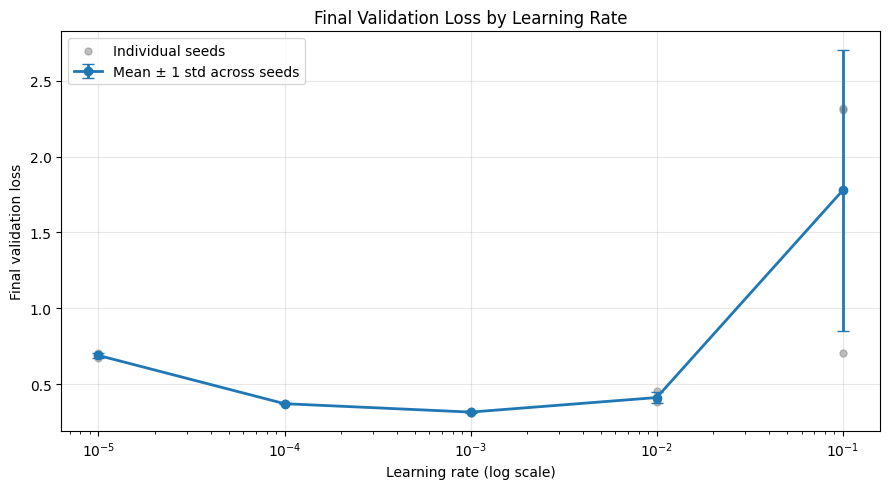

In [10]:
plot_df = results_df.dropna(subset=["final_val_loss_mean"]).copy()
completed_runs = per_run_df[per_run_df["status"] == "completed"]

plt.figure(figsize=(9, 5))
plt.errorbar(
    plot_df["learning_rate"],
    plot_df["final_val_loss_mean"],
    yerr=plot_df["final_val_loss_std"].fillna(0),
    marker="o",
    linewidth=2,
    capsize=4,
    label="Mean ± 1 std across seeds"
)
plt.scatter(
    completed_runs["learning_rate"],
    completed_runs["final_val_loss"],
    color="gray",
    alpha=0.5,
    s=25,
    label="Individual seeds"
)
plt.xscale("log")
plt.xlabel("Learning rate (log scale)")
plt.ylabel("Final validation loss")
plt.title("Final Validation Loss by Learning Rate")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Final validation loss for each learning rate (log-scale x-axis), using only runs that completed all four epochs. The line shows the mean across completed seeds, the error bars show ±1 standard deviation, and the gray dots are individual completed runs. Lower validation loss indicates lower classification error on this validation subset at the end of the four-epoch run; the result is specific to this experiment's settings.


## 13. Examine possible instability

For this experiment, treat instability as an **observed training behavior**, not simply a label attached to a large learning rate.

Evidence may include:
- training or validation loss that rises sharply or fluctuates substantially across epochs;
- loss becoming `NaN` or infinite, causing the run to stop;
- accuracy behaving erratically while loss changes sharply.

A single increase in loss does not automatically mean a run is unstable. The table below counts runs stopped by non-finite loss and separately counts runs with at least one epoch-to-epoch increase in training or validation loss. Those increases are signals to inspect in the curves, not proof of numerical instability.


In [11]:
stability_notes = []

for lr in LEARNING_RATES:
    non_finite = 0
    train_rise = 0
    val_rise = 0

    for seed in SEEDS:
        h = all_histories[(lr, seed)]
        if run_status[(lr, seed)].startswith("unstable: non-finite"):
            non_finite += 1
            continue
        if run_status[(lr, seed)] != "completed":
            continue
        if np.any(np.diff(np.array(h["train_loss"], dtype=float)) > 0):
            train_rise += 1
        if np.any(np.diff(np.array(h["val_loss"], dtype=float)) > 0):
            val_rise += 1

    total = len(SEEDS)
    stability_notes.append({
        "learning_rate": lr,
        "seeds_with_non_finite_loss": f"{non_finite}/{total}",
        "seeds_with_train_loss_increase": f"{train_rise}/{total}",
        "seeds_with_val_loss_increase": f"{val_rise}/{total}"
    })

stability_df = pd.DataFrame(stability_notes)
display(stability_df)

,learning_rate,seeds_with_non_finite_loss,seeds_with_train_loss_increase,seeds_with_val_loss_increase
0,0.00001,0/3,0/3,0/3
1,0.00010,0/3,0/3,0/3
2,0.00100,0/3,0/3,0/3
3,0.01000,0/3,0/3,0/3
4,0.10000,0/3,1/3,3/3


The results show that the learning rate affected how consistently the CNN learned during training.

The learning rate of **0.00001** showed stable but slower learning, with training and validation loss decreasing across the epochs. The learning rates of **0.0001 and 0.001** also showed consistent improvements, with **0.001 achieving the best overall results**, having the lowest mean validation loss and highest mean validation accuracy.

At **0.01**, the model still learned, but its performance was lower and more variable across the three seeds. The learning rate of **0.1 showed the clearest signs of instability**. All three runs experienced an increase in validation loss, while one run also had an increase in training loss. Although no run produced NaN or infinite loss, the results were less consistent across seeds.

Overall, the experiment suggests that a learning rate that is too small can slow down learning, while a learning rate that is too large can make training less consistent. Among the tested settings, **0.001 provided the most reliable performance** for this CNN and dataset.

## **Now it's your turn to experiment!**

Try changing the learning rates and see how the results change. You can test values higher or lower than the ones used in this experiment, then compare the training and validation curves. Observe how quickly the model learns and whether its training becomes more or less stable. What happens when you increase or decrease the learning rate?

## 14. Experiment limitations

- **Small subset:** Only 10,000 training images and 6,000 validation images were used, rather than the full Fashion-MNIST training set.
- **Short training:** Four epochs may be too few for some learning rates to reach their best performance.
- **Only three seeds:** Three seeds give a rough idea of run-to-run variation, but too few to estimate it precisely or to run formal statistical tests. The data split is also fixed, so variation caused by choosing different training images is not measured.
- **One model and optimizer:** The findings apply to this CNN and Adam setup; another architecture or optimizer may behave differently.
- **Learning-rate range:** The five tested values do not cover every possible learning rate.

A limitation does not make the experiment invalid. It defines what conclusions the experiment can reasonably support.